### Section 1: Setup + Load Features

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

PROJECT_PATH = '/content/drive/MyDrive/inflation-nowcast-th'
df = pd.read_csv(f'{PROJECT_PATH}/data/features_dataset.csv', parse_dates=['date'])
df = df.set_index('date')
df.shape

Mounted at /content/drive


(67, 15)

### Section 2: Time-based Train/Test Split

In [2]:
split_point = len(df) - 13

train = df.iloc[:split_point]
test = df.iloc[split_point:]

print(f"Train: {train.index.min()} ถึง {train.index.max()} ({len(train)} เดือน)")
print(f"Test:  {test.index.min()} ถึง {test.index.max()} ({len(test)} เดือน)")

Train: 2021-02-01 00:00:00 ถึง 2025-07-01 00:00:00 (54 เดือน)
Test:  2025-08-01 00:00:00 ถึง 2026-08-01 00:00:00 (13 เดือน)


In [3]:
feature_cols = ['policy_rate_lag3', 'policy_rate_lag6', 'fx_lag1',
                'fx_pct_change_1m', 'fx_pct_change_3m', 'cpi_yoy_lag1']
target_col = 'cpi_yoy'

X_train, y_train = train[feature_cols], train[target_col]
X_test, y_test = test[feature_cols], test[target_col]

### Section 3: Baseline Model (Naive Forecast)

In [4]:
baseline_pred = X_test['cpi_yoy_lag1']

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))

print(f"Baseline MAE:  {baseline_mae:.3f}")
print(f"Baseline RMSE: {baseline_rmse:.3f}")

Baseline MAE:  0.505
Baseline RMSE: 0.897


### Section 4: ทดลองโมเดลจริง (Linear Regression + Random Forest)

In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

results = []

# --- Linear Regression ---
lr = LinearRegression()
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)

mae_lr = mean_absolute_error(y_test, pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, pred_lr))
results.append({'model': 'Linear Regression', 'MAE': mae_lr, 'RMSE': rmse_lr})

# --- Random Forest ---
rf = RandomForestRegressor(n_estimators=200, max_depth=4, random_state=42)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

mae_rf = mean_absolute_error(y_test, pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, pred_rf))
results.append({'model': 'Random Forest', 'MAE': mae_rf, 'RMSE': rmse_rf})

In [6]:
results.append({'model': 'Baseline (Naive)', 'MAE': baseline_mae, 'RMSE': baseline_rmse})

df_results = pd.DataFrame(results).sort_values('MAE').reset_index(drop=True)
print(df_results)

               model       MAE      RMSE
0      Random Forest  0.329678  0.489504
1   Baseline (Naive)  0.504520  0.896904
2  Linear Regression  0.628809  0.838750


### Section 5: Feature Importance

In [7]:
# Linear Regression - ดูทิศทาง (บวก/ลบ) และขนาดผลกระทบ
coef_df = pd.DataFrame({
    'feature': feature_cols,
    'coefficient': lr.coef_
}).sort_values('coefficient', key=abs, ascending=False)
print("Linear Regression Coefficients:")
print(coef_df)

Linear Regression Coefficients:
            feature  coefficient
0  policy_rate_lag3    -1.641565
1  policy_rate_lag6     1.052158
5      cpi_yoy_lag1     0.785519
2           fx_lag1     0.141033
4  fx_pct_change_3m     0.014515
3  fx_pct_change_1m    -0.011541


In [8]:
# Random Forest - ดูว่าตัวไหนโมเดลให้น้ำหนักมากสุด
importance_df = pd.DataFrame({
    'feature': feature_cols,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)
print("Random Forest Feature Importance:")
print(importance_df)

Random Forest Feature Importance:
            feature  importance
5      cpi_yoy_lag1    0.888333
0  policy_rate_lag3    0.035331
4  fx_pct_change_3m    0.032362
2           fx_lag1    0.021505
3  fx_pct_change_1m    0.012364
1  policy_rate_lag6    0.010105


In [9]:
# ทดสอบ Model โดยไม่มี cpi_yoy_lag1 (ดูว่า proxy variables มีประโยชน์แค่ไหน)

feature_cols_no_lag = ['policy_rate_lag3', 'policy_rate_lag6', 'fx_lag1',
                        'fx_pct_change_1m', 'fx_pct_change_3m']

X_train2 = train[feature_cols_no_lag]
X_test2 = test[feature_cols_no_lag]

rf2 = RandomForestRegressor(n_estimators=200, max_depth=4, random_state=42)
rf2.fit(X_train2, y_train)
pred_rf2 = rf2.predict(X_test2)

mae_rf2 = mean_absolute_error(y_test, pred_rf2)
rmse_rf2 = np.sqrt(mean_squared_error(y_test, pred_rf2))

print(f"Random Forest (ไม่มี cpi_yoy_lag1) - MAE: {mae_rf2:.3f}, RMSE: {rmse_rf2:.3f}")
print(f"เทียบกับ Baseline MAE: {baseline_mae:.3f}")

importance_df2 = pd.DataFrame({
    'feature': feature_cols_no_lag,
    'importance': rf2.feature_importances_
}).sort_values('importance', ascending=False)
print(importance_df2)

Random Forest (ไม่มี cpi_yoy_lag1) - MAE: 0.626, RMSE: 0.755
เทียบกับ Baseline MAE: 0.505
            feature  importance
0  policy_rate_lag3    0.360553
2           fx_lag1    0.312918
1  policy_rate_lag6    0.165174
4  fx_pct_change_3m    0.111135
3  fx_pct_change_1m    0.050219


In [10]:
# ทดสอบว่า oil price ช่วยจริงไหม (ไม่มี cpi_yoy_lag1 เหมือนตอนทดสอบก่อนหน้า)
feature_cols_with_oil = ['policy_rate_lag3', 'policy_rate_lag6', 'fx_lag1',
                          'fx_pct_change_1m', 'fx_pct_change_3m',
                          'oil_lag1', 'oil_pct_change_1m', 'oil_pct_change_3m']

all_cols_for_rf3 = feature_cols_with_oil + ['cpi_yoy']
df_feat = df[all_cols_for_rf3].dropna()

split_point2 = len(df_feat) - 13
train2 = df_feat.iloc[:split_point2]
test2 = df_feat.iloc[split_point2:]

X_train3 = train2[feature_cols_with_oil]
X_test3 = test2[feature_cols_with_oil]
y_train3 = train2['cpi_yoy']
y_test3 = test2['cpi_yoy']

rf3 = RandomForestRegressor(n_estimators=200, max_depth=4, random_state=42)
rf3.fit(X_train3, y_train3)
pred_rf3 = rf3.predict(X_test3)

mae_rf3 = mean_absolute_error(y_test3, pred_rf3)
print(f"Random Forest + Oil (ไม่มี cpi_yoy_lag1) - MAE: {mae_rf3:.3f}")
print(f"เทียบ Baseline MAE: {baseline_mae:.3f}")
print(f"เทียบ Proxy เดิม (ไม่มี oil) MAE: 0.626")

importance_df3 = pd.DataFrame({
    'feature': feature_cols_with_oil,
    'importance': rf3.feature_importances_
}).sort_values('importance', ascending=False)
print(importance_df3)

Random Forest + Oil (ไม่มี cpi_yoy_lag1) - MAE: 0.915
เทียบ Baseline MAE: 0.505
เทียบ Proxy เดิม (ไม่มี oil) MAE: 0.626
             feature  importance
5           oil_lag1    0.550842
0   policy_rate_lag3    0.192201
1   policy_rate_lag6    0.107300
2            fx_lag1    0.047874
4   fx_pct_change_3m    0.038372
7  oil_pct_change_3m    0.027803
3   fx_pct_change_1m    0.025206
6  oil_pct_change_1m    0.010401


### Section 6: Oil Lag Sweep (EXPLORATION ONLY)

In [11]:
# โหลด master เพื่อให้ oil_price มีประวัติก่อน 2021-02
master = pd.read_csv(f'{PROJECT_PATH}/data/master_dataset.csv', parse_dates=['date']).set_index('date')

def eval_rf(Xtr, Xte):
    m = RandomForestRegressor(n_estimators=200, max_depth=4, random_state=42)
    m.fit(Xtr, y_train)
    p = m.predict(Xte)
    return mean_absolute_error(y_test, p), np.sqrt(mean_squared_error(y_test, p))

rows = []
for use_cpi_lag in [False, True]:
    cols = feature_cols_no_lag + (['cpi_yoy_lag1'] if use_cpi_lag else [])

    # อ้างอิง: ไม่มีน้ำมันเลย (oil_lag = 0 หมายถึงไม่ใช้น้ำมัน)
    mae, rmse = eval_rf(train[cols], test[cols])
    rows.append({'oil_lag': 0, 'with_cpi_lag1': use_cpi_lag, 'MAE': mae, 'RMSE': rmse})

    for lag in range(1, 7):
        oil_lagged = master['oil_price'].shift(lag).reindex(df.index)
        Xtr = train[cols].copy()
        Xte = test[cols].copy()
        Xtr['oil_lag'] = oil_lagged.loc[train.index]
        Xte['oil_lag'] = oil_lagged.loc[test.index]
        mae, rmse = eval_rf(Xtr, Xte)
        rows.append({'oil_lag': lag, 'with_cpi_lag1': use_cpi_lag, 'MAE': mae, 'RMSE': rmse})

df_sweep = pd.DataFrame(rows)
print("MAE:")
print(df_sweep.pivot(index='oil_lag', columns='with_cpi_lag1', values='MAE').round(3))
print("\nRMSE:")
print(df_sweep.pivot(index='oil_lag', columns='with_cpi_lag1', values='RMSE').round(3))
print(f"\nBaseline MAE: {baseline_mae:.3f}")

MAE:
with_cpi_lag1  False  True 
oil_lag                    
0              0.626  0.330
1              0.928  0.341
2              1.127  0.327
3              1.339  0.334
4              1.125  0.357
5              0.706  0.358
6              0.610  0.344

RMSE:
with_cpi_lag1  False  True 
oil_lag                    
0              0.755  0.490
1              1.226  0.537
2              1.519  0.510
3              1.811  0.528
4              1.551  0.548
5              0.851  0.552
6              0.726  0.539

Baseline MAE: 0.505


### Section 7: Walk-forward backtest (expanding window, ทำนายทีละเดือน)

In [12]:
candidates = {
    'RF: CPI lag1 only': ['cpi_yoy_lag1'],
    'RF: CPI lag1 + proxies': ['cpi_yoy_lag1'] + feature_cols_no_lag,
    'RF: proxies only': feature_cols_no_lag,
}

min_train = 36   # เทรนเริ่มต้น 36 เดือน ได้ทำนาย 31 เดือน
dates = df.index[min_train:]

preds = pd.DataFrame(index=dates)
preds['actual'] = df.loc[dates, 'cpi_yoy']
preds['naive'] = df.loc[dates, 'cpi_yoy_lag1']

for name, cols in candidates.items():
    out = []
    for i in range(min_train, len(df)):
        tr, te = df.iloc[:i], df.iloc[[i]]          # เทรนเฉพาะอดีต ทำนายเดือน i
        m = RandomForestRegressor(n_estimators=200, max_depth=4, random_state=42)
        m.fit(tr[cols], tr['cpi_yoy'])
        out.append(m.predict(te[cols])[0])
    preds[name] = out

rows = []
for c in preds.columns.drop('actual'):
    e = preds['actual'] - preds[c]
    rows.append({'model': c, 'MAE': e.abs().mean(), 'RMSE': np.sqrt((e**2).mean())})
print(pd.DataFrame(rows).sort_values('MAE').round(3))

preds.reset_index().to_csv(f'{PROJECT_PATH}/data/walk_forward_predictions.csv', index=False)

                    model    MAE   RMSE
2  RF: CPI lag1 + proxies  0.356  0.499
1       RF: CPI lag1 only  0.397  0.509
3        RF: proxies only  0.454  0.600
0                   naive  0.465  0.717


### Section 8: Error analysis (จากผล walk-forward)

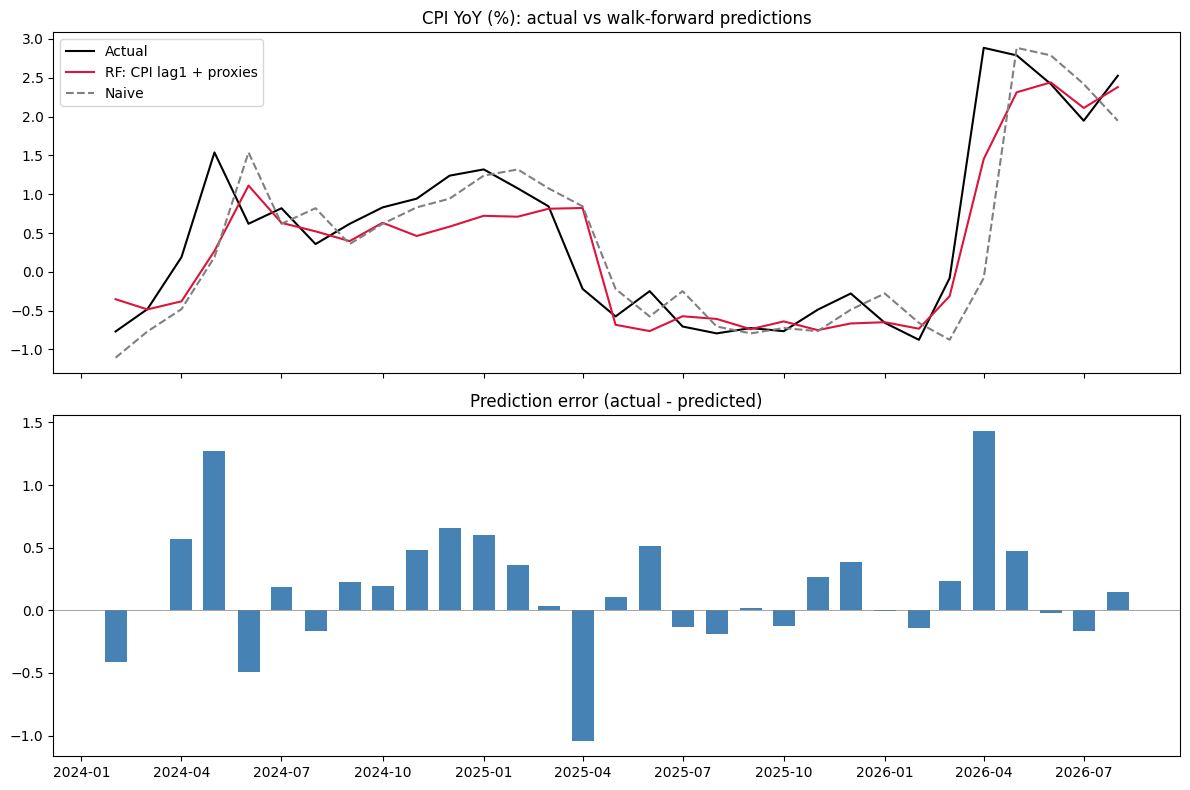

            actual  RF: CPI lag1 + proxies  naive  error
date                                                    
2026-04-01    2.89                    1.45  -0.08   1.43
2024-05-01    1.54                    0.27   0.19   1.27
2025-04-01   -0.22                    0.82   0.84  -1.04
2024-12-01    1.24                    0.58   0.94   0.66
2025-01-01    1.32                    0.72   1.24   0.60
2024-04-01    0.19                   -0.38  -0.48   0.57
2025-06-01   -0.25                   -0.76  -0.57   0.51
2024-06-01    0.62                    1.11   1.54  -0.49
proxies ชนะ 19 จาก 31 เดือน
ส่วนต่าง MAE เฉลี่ย: 0.041 | 95% CI: [-0.061  0.139]


In [13]:
import matplotlib.pyplot as plt

wf = pd.read_csv(f'{PROJECT_PATH}/data/walk_forward_predictions.csv', parse_dates=['date']).set_index('date')
best = 'RF: CPI lag1 + proxies'

# กราฟ 1-2: actual vs predicted และ error ตามเวลา
fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
ax[0].plot(wf.index, wf['actual'], label='Actual', color='black')
ax[0].plot(wf.index, wf[best], label=best, color='crimson')
ax[0].plot(wf.index, wf['naive'], label='Naive', color='gray', linestyle='--')
ax[0].legend()
ax[0].set_title('CPI YoY (%): actual vs walk-forward predictions')

err = wf['actual'] - wf[best]
ax[1].bar(wf.index, err, width=20, color='steelblue')
ax[1].axhline(0, color='gray', linewidth=0.5)
ax[1].set_title('Prediction error (actual - predicted)')
plt.tight_layout()
plt.show()

# ตาราง: เดือนที่พลาดหนักสุด
top = wf.assign(error=err, abs_error=err.abs()).sort_values('abs_error', ascending=False).head(8)
print(top[['actual', best, 'naive', 'error']].round(2))

# เทียบรายเดือน: มี proxies ดีกว่า lag1-only กี่เดือน
e_a = (wf['actual'] - wf['RF: CPI lag1 + proxies']).abs()
e_b = (wf['actual'] - wf['RF: CPI lag1 only']).abs()
print(f"proxies ชนะ {(e_a < e_b).sum()} จาก {len(wf)} เดือน")

# bootstrap แบบง่าย ดูความไม่แน่นอนของส่วนต่าง MAE
rng = np.random.default_rng(42)
diff = (e_b - e_a).values
boot = [rng.choice(diff, size=len(diff), replace=True).mean() for _ in range(5000)]
print("ส่วนต่าง MAE เฉลี่ย:", diff.mean().round(3), "| 95% CI:", np.percentile(boot, [2.5, 97.5]).round(3))

### Section 9: v2 — ทำนาย MoM แล้วแปลงเป็น YoY ด้วย base effect ที่รู้อยู่แล้ว

In [14]:
master = pd.read_csv(f'{PROJECT_PATH}/data/master_dataset.csv', parse_dates=['date']).set_index('date')

V = df.copy()   # 67 เดือนเดิม ประเมิน 31 เดือนเดียวกับ v1 เทียบกันตรง ๆ ได้
V['mom']        = master['cpi_mom'].reindex(V.index)
V['mom_lag1']   = master['cpi_mom'].shift(1).reindex(V.index)
V['yoy_prev']   = master['cpi_yoy'].shift(1).reindex(V.index)
V['mom_prev12'] = master['cpi_mom'].shift(12).reindex(V.index)

def to_yoy(mom_hat, yoy_prev, mom_prev12):
    return ((1 + yoy_prev/100) * (1 + mom_hat/100) / (1 + mom_prev12/100) - 1) * 100

# sanity check: ใช้ MoM จริงแล้วต้องสร้าง YoY จริงกลับมาได้ (ควรใกล้ 0)
chk = to_yoy(V['mom'], V['yoy_prev'], V['mom_prev12'])
print("max reconstruction error:", (chk - V['cpi_yoy']).abs().max())

min_train = 36
dates = V.index[min_train:]
res = pd.DataFrame(index=dates)
res['actual'] = V.loc[dates, 'cpi_yoy']

# v1 (จากไฟล์เดิม) + baselines
wf = pd.read_csv(f'{PROJECT_PATH}/data/walk_forward_predictions.csv', parse_dates=['date']).set_index('date')
res['v1: RF CPI lag1 + proxies'] = wf.loc[dates, 'RF: CPI lag1 + proxies']
res['naive YoY']                  = V.loc[dates, 'cpi_yoy_lag1']
yp, mp12 = V.loc[dates, 'yoy_prev'], V.loc[dates, 'mom_prev12']
res['base-effect naive: MoM=0']   = to_yoy(0, yp, mp12)
res['base-effect naive: MoM=last']= to_yoy(V.loc[dates, 'mom_lag1'], yp, mp12)

# v2: RF ทำนาย MoM แล้วแปลงเป็น YoY
cands = {
    'v2 RF: MoM lag1':            ['mom_lag1'],
    'v2 RF: MoM lag1 + proxies':  ['mom_lag1'] + feature_cols_no_lag,
}
for name, cols in cands.items():
    out = []
    for i in range(min_train, len(V)):
        tr, te = V.iloc[:i], V.iloc[[i]]
        m = RandomForestRegressor(n_estimators=200, max_depth=4, random_state=42)
        m.fit(tr[cols], tr['mom'])
        out.append(to_yoy(m.predict(te[cols])[0], te['yoy_prev'].iloc[0], te['mom_prev12'].iloc[0]))
    res[name] = out

rows = []
for c in res.columns.drop('actual'):
    e = res['actual'] - res[c]
    rows.append({'model': c, 'MAE': e.abs().mean(), 'RMSE': np.sqrt((e**2).mean())})
print(pd.DataFrame(rows).sort_values('MAE').round(3))

res.reset_index().to_csv(f'{PROJECT_PATH}/data/walk_forward_v2.csv', index=False)

max reconstruction error: 4.440892098500626e-14
                         model    MAE   RMSE
2     base-effect naive: MoM=0  0.319  0.589
0    v1: RF CPI lag1 + proxies  0.356  0.499
5    v2 RF: MoM lag1 + proxies  0.365  0.648
4              v2 RF: MoM lag1  0.393  0.624
3  base-effect naive: MoM=last  0.446  0.746
1                    naive YoY  0.465  0.717


### Section 10: paired bootstrap + sensitivity (ตัด เม.ย. 2026)

In [15]:
res = pd.read_csv(f'{PROJECT_PATH}/data/walk_forward_v2.csv', parse_dates=['date']).set_index('date')
models = res.columns.drop('actual')
ref = 'base-effect naive: MoM=0'
rng = np.random.default_rng(42)

def paired_boot(d, n=5000):
    d = np.asarray(d)
    b = [rng.choice(d, size=len(d), replace=True).mean() for _ in range(n)]
    return d.mean(), np.percentile(b, [2.5, 97.5])

print(f"ส่วนต่างเทียบกับ '{ref}' (ค่าบวก = โมเดลนี้พลาดมากกว่า)")
for m in models.drop(ref):
    d_abs = (res['actual'] - res[m]).abs() - (res['actual'] - res[ref]).abs()
    mean, ci = paired_boot(d_abs)
    print(f"{m:32s} ΔMAE = {mean:+.3f}  95% CI [{ci[0]:+.3f}, {ci[1]:+.3f}]")

# sensitivity: ไม่รวม 2026-04 (ใช้ดูความเปราะบางเท่านั้น ไม่ใช่ผลหลัก)
r2 = res.drop(pd.Timestamp('2026-04-01'))
rows = []
for c in models:
    e = r2['actual'] - r2[c]
    rows.append({'model': c, 'MAE': e.abs().mean(), 'RMSE': np.sqrt((e**2).mean())})
print("\nไม่รวม 2026-04:")
print(pd.DataFrame(rows).sort_values('MAE').round(3))

ส่วนต่างเทียบกับ 'base-effect naive: MoM=0' (ค่าบวก = โมเดลนี้พลาดมากกว่า)
v1: RF CPI lag1 + proxies        ΔMAE = +0.037  95% CI [-0.111, +0.179]
naive YoY                        ΔMAE = +0.146  95% CI [+0.068, +0.233]
base-effect naive: MoM=last      ΔMAE = +0.127  95% CI [-0.022, +0.323]
v2 RF: MoM lag1                  ΔMAE = +0.074  95% CI [+0.008, +0.144]
v2 RF: MoM lag1 + proxies        ΔMAE = +0.046  95% CI [-0.031, +0.139]

ไม่รวม 2026-04:
                         model    MAE   RMSE
2     base-effect naive: MoM=0  0.238  0.324
5    v2 RF: MoM lag1 + proxies  0.286  0.429
4              v2 RF: MoM lag1  0.315  0.388
0    v1: RF CPI lag1 + proxies  0.321  0.434
1                    naive YoY  0.382  0.487
3  base-effect naive: MoM=last  0.389  0.648


### Section 11: สรุปผลสุดท้าย + ไฟล์สำหรับ dashboard

In [16]:
res = pd.read_csv(f'{PROJECT_PATH}/data/walk_forward_v2.csv', parse_dates=['date']).set_index('date')
ref = 'base-effect naive: MoM=0'
models = res.columns.drop('actual')
rng = np.random.default_rng(42)
ex = res.index != pd.Timestamp('2026-04-01')

rows = []
for m in models:
    e = res['actual'] - res[m]
    d = e.abs() - (res['actual'] - res[ref]).abs()
    boot = [rng.choice(d.values, size=len(d), replace=True).mean() for _ in range(5000)]
    lo, hi = np.percentile(boot, [2.5, 97.5])
    rows.append({
        'model': m,
        'MAE': e.abs().mean(), 'RMSE': np.sqrt((e**2).mean()),
        'MAE_ex_2026-04': e[ex].abs().mean(), 'RMSE_ex_2026-04': np.sqrt((e[ex]**2).mean()),
        'dMAE_vs_ref': d.mean(), 'dMAE_lo': lo, 'dMAE_hi': hi,
    })
summary = pd.DataFrame(rows).sort_values('MAE').round(3)
print(summary)
summary.to_csv(f'{PROJECT_PATH}/data/results_summary.csv', index=False)

# แยกการเปลี่ยนของ YoY: ส่วน MoM จริง + ส่วน base effect (ประมาณแบบบวก)
master = pd.read_csv(f'{PROJECT_PATH}/data/master_dataset.csv', parse_dates=['date']).set_index('date')
dec = pd.DataFrame({
    'cpi_yoy': master['cpi_yoy'],
    'yoy_change': master['cpi_yoy'].diff(),
    'mom_component': master['cpi_mom'],
    'base_component': -master['cpi_mom'].shift(12),
}).dropna()
dec['residual'] = dec['yoy_change'] - dec['mom_component'] - dec['base_component']
print(dec.tail(6).round(2))
print("max |residual|:", round(float(dec['residual'].abs().max()), 3))
dec.reset_index().to_csv(f'{PROJECT_PATH}/data/yoy_decomposition.csv', index=False)

                         model    MAE   RMSE  MAE_ex_2026-04  RMSE_ex_2026-04  \
2     base-effect naive: MoM=0  0.319  0.589           0.238            0.324   
0    v1: RF CPI lag1 + proxies  0.356  0.499           0.321            0.434   
5    v2 RF: MoM lag1 + proxies  0.365  0.648           0.286            0.429   
4              v2 RF: MoM lag1  0.393  0.624           0.315            0.388   
3  base-effect naive: MoM=last  0.446  0.746           0.389            0.648   
1                    naive YoY  0.465  0.717           0.382            0.487   

   dMAE_vs_ref  dMAE_lo  dMAE_hi  
2        0.000    0.000    0.000  
0        0.037   -0.111    0.179  
5        0.046   -0.032    0.133  
4        0.074    0.008    0.143  
3        0.127   -0.022    0.326  
1        0.146    0.068    0.233  
            cpi_yoy  yoy_change  mom_component  base_component  residual
date                                                                    
2026-03-01    -0.08        0.80          

### Section 12: เตรียมไฟล์รูปแบบ long สำหรับ Tableau

In [17]:
res = pd.read_csv(f'{PROJECT_PATH}/data/walk_forward_v2.csv', parse_dates=['date'])
wf_long = res.melt(id_vars=['date', 'actual'], var_name='model', value_name='predicted')
wf_long['error'] = wf_long['actual'] - wf_long['predicted']
wf_long['abs_error'] = wf_long['error'].abs()
wf_long.to_csv(f'{PROJECT_PATH}/data/tableau_walk_forward_long.csv', index=False)

dec = pd.read_csv(f'{PROJECT_PATH}/data/yoy_decomposition.csv', parse_dates=['date'])
dec_long = dec.melt(id_vars=['date', 'cpi_yoy', 'yoy_change'],
                    value_vars=['mom_component', 'base_component'],
                    var_name='component', value_name='contribution')
dec_long['component'] = dec_long['component'].map({
    'mom_component': 'MoM (ราคาเปลี่ยนเดือนนี้)',
    'base_component': 'Base effect (เดือนเดียวกันปีก่อน)'})
dec_long.to_csv(f'{PROJECT_PATH}/data/tableau_yoy_decomposition_long.csv', index=False)

print(wf_long.shape, dec_long.shape)

(186, 6) (134, 5)


### Section 13: ไฟล์สำหรับกราฟเส้น actual vs predicted

In [18]:
res = pd.read_csv(f'{PROJECT_PATH}/data/walk_forward_v2.csv', parse_dates=['date'])
series = res.melt(id_vars=['date'], var_name='series', value_name='value')   # actual กลายเป็นหนึ่งใน series
series['series'] = series['series'].replace({'actual': 'Actual (CPI YoY)'})
series.to_csv(f'{PROJECT_PATH}/data/tableau_actual_vs_pred_long.csv', index=False)
print(series['series'].unique())

['Actual (CPI YoY)' 'v1: RF CPI lag1 + proxies' 'naive YoY'
 'base-effect naive: MoM=0' 'base-effect naive: MoM=last'
 'v2 RF: MoM lag1' 'v2 RF: MoM lag1 + proxies']
